# PlantSeg -- Array 2nd-Revision Notebook E: ViT-B/16 + Swin-Tiny seed-42 RETRAIN
## (replaces the two broken seed-42 classifier checkpoints with freshly-trained ones)

**Why this notebook exists.** A three-notebook investigation (C, D, D2) has now exhausted every
evaluation-side explanation for why the seed-42 `ViTBase16_best.pt` / `SwinTiny_best.pt`
classifier checkpoints score near chance: checkpoint structure is byte-identical across seeds,
behavior is byte-identical across 5 real `timm` versions, class mapping and image resolution
match training exactly, raw tensor values show no corruption (no NaN/Inf/zero, magnitudes close
to the known-good seed-123/seed-7 checkpoints) -- and, decisively, **both models fail to fit
their own training images** (ViT: 12.5% top-1 / 32.5% top-5 on train; Swin: 0.83% top-1 / 3.33%
top-5 on train, with SwinTiny's predictions collapsed onto just 4-5 of 115 classes). That rules
out evaluation entirely. The problem is in how these two checkpoints were produced during the
original June training run.

**What this notebook does.** Re-runs training for **only** ViT-B/16 and Swin-Tiny, seed 42,
using the *exact* recipe lifted verbatim from the original training notebook
(`PlantSeg_S1_Session2_Train_Models5to8.ipynb`): same `SCOPE="full"`, same 224x224 resolution,
same `is_tf` branch (`lr=5e-5`, 3-epoch warmup, patience=10, up to 40 epochs), same optimizer /
scheduler / augmentation / class-weighting / label smoothing. Nothing about the recipe is
changed -- only the two model names being trained. This exact recipe already produced solid,
reviewer-facing numbers for these same two architectures at seed 123 (75.1%/72.9% val acc) and
seed 7 (76.6%/73.5% val acc), so it is proven to converge properly on this dataset.

**Expected runtime.** Based on the real `train_time_sec` logged by the seed-123/seed-7 runs:
ViT-B/16 reliably uses its full 40-epoch budget (~43-47 min), Swin-Tiny early-stops in the
high-20s/low-30s epochs (~27-33 min). **Total: roughly 70-80 minutes** on a single Kaggle T4/P100
GPU session, comfortably within the free quota.

**Output files** (same naming convention as the original seed-42 run -- no seed suffix, since
seed 42 is the main-text seed -- so these drop straight back into the existing pipeline in place
of the broken ones): `ViTBase16_best.pt`, `SwinTiny_best.pt`, `result_ViTBase16.pkl`,
`result_SwinTiny.pkl`, plus the usual per-model figures.

**Built-in sanity check.** The last cell re-runs the exact collapse-vs-scatter diagnostic from
Notebook D2 (quick 120-image train + val subsets, same fixed seed) on the freshly-trained models
*before* you even need to download anything -- so you'll know immediately, from this notebook's
own output, whether the fix worked.

## Section 1 -- Install Dependencies & Imports (identical to the original training notebook)

In [1]:
!pip install -q timm imagehash statsmodels grad-cam
import os, json, math, time, random, warnings, pickle, glob
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision; from torchvision import transforms
import timm
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, matthews_corrcoef, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, auc)
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="talk")

SEED = 42  # matches the original seed-42 run exactly -- this IS the main-text seed, not a new one
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("Device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.1 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Device: cuda


## Section 2 -- Global Configuration (same hyperparameters as the original run)

In [2]:
# ============ CONFIG ============
def find_data_root():
    for cand in [Path("/kaggle/input/datasets/alenmaruf/plantseg/plantseg"),
                 Path("/kaggle/input/plantseg/plantseg"), Path("/kaggle/input/plantseg"),
                 Path("plantseg"), Path(".")]:
        if (cand/"Metadata.csv").exists(): return cand
    hits = glob.glob("/kaggle/input/**/Metadata.csv", recursive=True)
    assert hits, "Metadata.csv not found anywhere under /kaggle/input -- attach the PlantSeg dataset."
    return Path(hits[0]).parent

DATA_ROOT = find_data_root()
print("DATA_ROOT:", DATA_ROOT)

OUTDIR = Path("/kaggle/working/s1_seed42_retrain_results"); FIG = OUTDIR/"figures"
OUTDIR.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# Only the two broken models -- confirmed from the original training notebook, unchanged otherwise.
MODELS_TO_TRAIN = ["ViTBase16", "SwinTiny"]

SCOPE = "full"   # confirmed via direct inspection of the original training notebook -- do not change
FRUIT_HOSTS = {"Apple","Citrus","Grape","Banana","Peach","Blueberry",
               "Plum","Cherry","Raspberry","Strawberry"}  # unused when SCOPE=="full"; kept for fidelity

NUM_EPOCHS      = 40
PATIENCE        = 8        # overridden to 10 below for transformer models, same as original
LR              = 3e-4     # overridden to 5e-5 below for transformer models, same as original
WEIGHT_DECAY    = 1e-4
USE_PRETRAINED  = True
USE_CLASS_WEIGHTS = True
LABEL_SMOOTHING = 0.05
USE_RANDAUG     = True
USE_TTA         = True
QUICK_SMOKE     = False

print("Models to retrain:", MODELS_TO_TRAIN)

DATA_ROOT: /kaggle/input/datasets/alenmaruf/plantseg/plantseg
Models to retrain: ['ViTBase16', 'SwinTiny']


## Section 3 -- Dataset Index & Class Weights (identical logic to the original run)

In [3]:
# ============ DATA INDEX ============
meta = pd.read_csv(DATA_ROOT/"Metadata.csv", encoding="utf-8-sig")
meta["split"] = meta["Split"].map({"Training":"train","Validation":"val","Test":"test"})
meta["filepath"] = meta.apply(lambda r: DATA_ROOT/"images"/r["split"]/r["Name"], axis=1)
meta["label"] = meta["Disease"]; meta["plant"] = meta["Plant"]
if SCOPE == "fruit":
    meta = meta[meta["plant"].isin(FRUIT_HOSTS)].reset_index(drop=True)
meta = meta[meta["filepath"].apply(lambda p: Path(p).exists())].reset_index(drop=True)

CLASS_NAMES = sorted(meta["label"].unique().tolist())
NUM_CLASSES = len(CLASS_NAMES)
label2idx = {c: i for i, c in enumerate(CLASS_NAMES)}

train_df = meta[meta.split=="train"].reset_index(drop=True)
val_df   = meta[meta.split=="val"].reset_index(drop=True)
test_df  = meta[meta.split=="test"].reset_index(drop=True)

if QUICK_SMOKE:
    train_df = train_df.groupby("label",group_keys=False).head(8).reset_index(drop=True)
    val_df   = val_df.groupby("label",group_keys=False).head(4).reset_index(drop=True)
    test_df  = test_df.groupby("label",group_keys=False).head(4).reset_index(drop=True)
    NUM_EPOCHS = 1

counts = train_df["label"].map(label2idx).value_counts().reindex(range(NUM_CLASSES)).fillna(0)
inv = np.where(counts.values > 0, 1.0/counts.values, 0.0)
cw  = inv / inv[inv>0].mean()
class_weights = torch.tensor(cw, dtype=torch.float32, device=device)

print(f"classes={NUM_CLASSES}  train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")

classes=115  train=5367  val=846  test=1561


## Section 4 -- Transforms & Dataset Class (identical to the original run)

In [4]:
# ============ TRANSFORMS / DATASET ============
MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]

def make_transforms(sz):
    ops = [transforms.RandomResizedCrop(sz, scale=(0.7,1.0)),
           transforms.RandomHorizontalFlip(),
           transforms.RandomVerticalFlip(p=0.2)]
    if USE_RANDAUG:
        ops += [transforms.RandAugment(num_ops=2, magnitude=9)]
    else:
        ops += [transforms.RandomRotation(15),
                transforms.ColorJitter(0.2, 0.2, 0.2, 0.05)]
    ops += [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    if USE_RANDAUG:
        ops += [transforms.RandomErasing(p=0.25)]
    ev = transforms.Compose([transforms.Resize((sz,sz)),
                             transforms.ToTensor(),
                             transforms.Normalize(MEAN, STD)])
    return transforms.Compose(ops), ev

class DS(Dataset):
    def __init__(self, d, t):
        self.df = d.reset_index(drop=True); self.t = t
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.t(Image.open(r.filepath).convert("RGB")), label2idx[r.label]

## Section 5 -- Model Zoo (only the two transformer branches needed here)

In [5]:
# ============ MODEL ZOO (ViT-B/16 + Swin-Tiny only) ============
def build_backbone(name, num_classes, pretrained=USE_PRETRAINED):
    if name == "ViTBase16":
        return timm.create_model("vit_base_patch16_224", pretrained=pretrained, num_classes=num_classes), 224, 16
    if name == "SwinTiny":
        return timm.create_model("swin_tiny_patch4_window7_224", pretrained=pretrained, num_classes=num_classes), 224, 16
    raise ValueError(name)

FUSION_MODELS = {}  # no fusion model in scope for this retrain

## Section 6 -- Training & Metric Helper Functions (byte-for-byte identical to the original
`train_one` / `deployment` / `compute_metrics` -- the only change anywhere in this notebook versus
the original training code is *which models get passed to this function* in Section 9 below)

In [6]:
# ============ TRAIN / METRICS HELPERS ============
def train_one(model_name, num_epochs=NUM_EPOCHS, patience=PATIENCE):
    if model_name in FUSION_MODELS:
        model = FUSION_MODELS[model_name](NUM_CLASSES).to(device); img_size, bs = 224, 16
    else:
        model, img_size, bs = build_backbone(model_name, NUM_CLASSES); model = model.to(device)
    ttf, etf = make_transforms(img_size)
    tl = DataLoader(DS(train_df, ttf), batch_size=bs, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
    vl = DataLoader(DS(val_df,   etf), batch_size=bs, shuffle=False, num_workers=2, pin_memory=True)
    te = DataLoader(DS(test_df,  etf), batch_size=bs, shuffle=False, num_workers=2, pin_memory=True)
    is_tf = model_name in ("ViTBase16","SwinTiny")
    lr = 5e-5 if is_tf else LR; warm_ep = 3 if is_tf else 2; pat = 10 if is_tf else patience
    opt  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    warm = torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.1, total_iters=warm_ep)
    cos  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, num_epochs-warm_ep))
    sch  = torch.optim.lr_scheduler.SequentialLR(opt, [warm, cos], milestones=[warm_ep])
    crit = nn.CrossEntropyLoss(weight=class_weights if USE_CLASS_WEIGHTS else None, label_smoothing=LABEL_SMOOTHING)
    scaler = torch.cuda.amp.GradScaler(enabled=device.type=="cuda")
    hist = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}; best=-1; best_state=None; bad=0
    for ep in range(num_epochs):
        model.train(); run=cor=tot=0
        for x,y in tl:
            x,y = x.to(device),y.to(device); opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item()*x.size(0); cor += (out.argmax(1)==y).sum().item(); tot += y.size(0)
        trl, tra = run/tot, cor/tot
        model.eval(); vr=vc=vt=0
        with torch.no_grad():
            for x,y in vl:
                x,y = x.to(device),y.to(device); out = model(x); loss = crit(out,y)
                vr += loss.item()*x.size(0); vc += (out.argmax(1)==y).sum().item(); vt += y.size(0)
        vlo, vac = vr/vt, vc/vt; sch.step()
        for k,v in zip(hist, [trl,vlo,tra,vac]): hist[k].append(v)
        print(f"[{model_name}] ep{ep+1}/{num_epochs} lr={opt.param_groups[0]['lr']:.1e} "
              f"trL={trl:.3f} vL={vlo:.3f} trA={tra:.3f} vA={vac:.3f}")
        if vac > best+1e-4:
            best=vac; best_state={k:v.cpu().clone() for k,v in model.state_dict().items()}; bad=0
        else:
            bad += 1
            if ep >= warm_ep and bad >= pat:
                print(f"  early stop @ ep{ep+1}"); break
    model.load_state_dict(best_state); torch.save(best_state, OUTDIR/f"{model_name}_best.pt")
    model.eval(); P=[]; Y=[]; PR=[]
    with torch.no_grad():
        for x,y in te:
            x = x.to(device); lg = model(x)
            if USE_TTA: lg = lg + model(torch.flip(x, dims=[3]))
            p = F.softmax(lg, 1).cpu().numpy(); P.extend(p.argmax(1)); Y.extend(y.numpy()); PR.extend(p)
    return model, img_size, hist, np.array(Y), np.array(P), np.array(PR)

def deployment(model, img_size, nw=5, ni=30):
    n = sum(p.numel() for p in model.parameters())
    tmp = OUTDIR/"_t.pt"; torch.save(model.state_dict(), tmp)
    sz = os.path.getsize(tmp)/1e6; os.remove(tmp)
    d  = torch.randn(1, 3, img_size, img_size)
    def t(dev):
        m = model.to(dev).eval(); dd = d.to(dev)
        with torch.no_grad():
            for _ in range(nw): m(dd)
            if dev.type=="cuda": torch.cuda.synchronize()
            t0 = time.time()
            for _ in range(ni): m(dd)
            if dev.type=="cuda": torch.cuda.synchronize()
            return (time.time()-t0)/ni*1000
    lg = t(device) if device.type=="cuda" else float("nan")
    lc = t(torch.device("cpu")); model.to(device)
    return {"params_M": n/1e6, "checkpoint_size_MB": sz, "latency_cpu_ms": lc, "latency_gpu_ms": lg}

def compute_metrics(y, yp, ypb, n):
    cm = confusion_matrix(y, yp, labels=range(n)); specs=[]
    for i in range(n):
        tn = cm.sum()-cm[i,:].sum()-cm[:,i].sum()+cm[i,i]; fp = cm[:,i].sum()-cm[i,i]
        specs.append(tn/(tn+fp) if (tn+fp)>0 else float("nan"))
    present = [c for c in range(n) if (y==c).sum()>0]; aucs=[]
    for c in present:
        try: aucs.append(roc_auc_score((y==c).astype(int), ypb[:,c]))
        except Exception: pass
    return {"accuracy": accuracy_score(y,yp),
            "balanced_accuracy": balanced_accuracy_score(y,yp),
            "f1_macro": f1_score(y,yp,average="macro"),
            "f1_weighted": f1_score(y,yp,average="weighted"),
            "precision_macro": precision_score(y,yp,average="macro",zero_division=0),
            "recall_macro": recall_score(y,yp,average="macro",zero_division=0),
            "mcc": matthews_corrcoef(y,yp),
            "roc_auc_macro": float(np.mean(aucs)) if aucs else float("nan"),
            "macro_specificity": float(np.nanmean(specs))}, cm

print("Training helpers ready.")

Training helpers ready.


## Section 7 -- Per-Model Figure Helper (identical to the original)

In [7]:
# ============ PER-MODEL FIGURE HELPER ============
def plot_model_figures(MODEL_NAME, hist, Y, P, PR, img_size):
    ep = range(1, len(hist["train_loss"])+1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="val")
    ax[0].set_title(f"{MODEL_NAME} -- loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
    ax[1].plot(ep, hist["train_acc"],  label="train"); ax[1].plot(ep, hist["val_acc"],  label="val")
    ax[1].set_title(f"{MODEL_NAME} -- accuracy"); ax[1].legend(); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(FIG/f"{MODEL_NAME}_loss_acc.png", dpi=200, bbox_inches="tight"); plt.show()

    cm = confusion_matrix(Y, P, labels=range(NUM_CLASSES))
    cmn = cm.astype(float)/cm.astype(float).sum(1, keepdims=True).clip(min=1)
    s = max(7, NUM_CLASSES*0.16)
    plt.figure(figsize=(s,s))
    sns.heatmap(cmn, cmap="viridis", square=True, cbar_kws={"shrink":0.5},
                xticklabels=CLASS_NAMES if NUM_CLASSES<=45 else False,
                yticklabels=CLASS_NAMES if NUM_CLASSES<=45 else False)
    plt.title(f"{MODEL_NAME} -- confusion (row-norm)"); plt.xlabel("predicted"); plt.ylabel("true")
    plt.tight_layout(); plt.savefig(FIG/f"{MODEL_NAME}_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

    y_oh = np.eye(NUM_CLASSES)[Y]; fpr,tpr,_ = roc_curve(y_oh.ravel(), PR.ravel()); micro = auc(fpr,tpr)
    present = [c for c in range(NUM_CLASSES) if (Y==c).sum()>0]
    macro_auc = np.mean([auc(*roc_curve((Y==c).astype(int), PR[:,c])[:2]) for c in present])
    plt.figure(figsize=(6.5,6))
    plt.plot(fpr, tpr, lw=2, label=f"micro (AUC={micro:.3f})")
    plt.plot([0,1],[0,1],"k--",lw=1)
    plt.title(f"{MODEL_NAME} -- ROC (macro-AUC={macro_auc:.3f})"); plt.xlabel("FPR"); plt.ylabel("TPR")
    plt.legend(loc="lower right"); plt.tight_layout()
    plt.savefig(FIG/f"{MODEL_NAME}_roc.png", dpi=200, bbox_inches="tight"); plt.show()

print("Figure helper ready.")

Figure helper ready.


## Section 8 -- Grad-CAM Helper (identical to the original -- will correctly no-op for
both models here, since the original notebook already skips Grad-CAM for transformer backbones
and defers to attention rollout in Stage 4; kept only for pipeline fidelity)

In [8]:
# ============ GRAD-CAM HELPER ============
def plot_gradcam(MODEL_NAME, model, img_size):
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.image import show_cam_on_image
    def _target_layers(m, name):
        if name == "ResNet50":          return [m.layer4[-1]]
        if name == "MobileNetV3Large":  return [m.features[-1]]
        if name == "ConvNeXtV2Tiny":    return [m.stages[-1]]
        if name in ("EfficientNetB0","EfficientNetV2S"): return [m.conv_head]
        if name == "GatedFusionLight":  return [m.branch_a.features[-1]]
        return None
    _, etf = make_transforms(img_size)
    tl_ = _target_layers(model, MODEL_NAME)
    if tl_ is None:
        print(f"{MODEL_NAME} is a transformer -- Grad-CAM skipped (use attention rollout in Stage 4).")
        return
    cam = GradCAM(model=model, target_layers=tl_)
    rows = test_df[test_df.plant.isin(FRUIT_HOSTS)].groupby("label").first().reset_index().head(6)
    fig, axes = plt.subplots(2, len(rows), figsize=(3.2*len(rows), 7))
    for col, (_, r) in zip(axes.T, rows.iterrows()):
        im = Image.open(r.filepath).convert("RGB").resize((img_size, img_size))
        g  = cam(input_tensor=etf(im).unsqueeze(0).to(device))[0]
        col[0].imshow(im); col[0].set_title(r.label, fontsize=8); col[0].axis("off")
        col[1].imshow(show_cam_on_image(np.float32(im)/255.0, g, use_rgb=True)); col[1].axis("off")
    plt.suptitle(f"Grad-CAM -- {MODEL_NAME}"); plt.tight_layout()
    plt.savefig(FIG/f"{MODEL_NAME}_gradcam.png", dpi=200, bbox_inches="tight"); plt.show()

print("Grad-CAM helper ready.")

Grad-CAM helper ready.


## Section 9 -- Training Loop: ViT-B/16 + Swin-Tiny ONLY, seed 42

Same loop structure as the original `MODELS_TO_TRAIN[4:]` loop, restricted to the two models in
scope. Output filenames match the original seed-42 convention exactly (no seed suffix) so they
replace the broken checkpoints in place.


  Training: ViTBase16  (seed=42)



model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

[ViTBase16] ep1/40 lr=2.0e-05 trL=4.710 vL=3.977 trA=0.075 vA=0.264
[ViTBase16] ep2/40 lr=3.5e-05 trL=2.698 vL=2.400 trA=0.473 vA=0.608
[ViTBase16] ep3/40 lr=5.0e-05 trL=1.857 vL=2.259 trA=0.669 vA=0.658
[ViTBase16] ep4/40 lr=5.0e-05 trL=1.708 vL=2.304 trA=0.719 vA=0.657
[ViTBase16] ep5/40 lr=5.0e-05 trL=1.426 vL=2.288 trA=0.804 vA=0.671
[ViTBase16] ep6/40 lr=4.9e-05 trL=1.263 vL=2.125 trA=0.857 vA=0.702
[ViTBase16] ep7/40 lr=4.9e-05 trL=1.259 vL=2.149 trA=0.864 vA=0.704
[ViTBase16] ep8/40 lr=4.8e-05 trL=1.173 vL=2.246 trA=0.898 vA=0.683
[ViTBase16] ep9/40 lr=4.7e-05 trL=1.119 vL=2.152 trA=0.904 vA=0.701
[ViTBase16] ep10/40 lr=4.6e-05 trL=1.108 vL=2.156 trA=0.915 vA=0.715
[ViTBase16] ep11/40 lr=4.4e-05 trL=1.072 vL=2.115 trA=0.924 vA=0.735
[ViTBase16] ep12/40 lr=4.3e-05 trL=1.073 vL=2.178 trA=0.923 vA=0.710
[ViTBase16] ep13/40 lr=4.2e-05 trL=1.040 vL=2.173 trA=0.933 vA=0.713
[ViTBase16] ep14/40 lr=4.0e-05 trL=0.997 vL=2.192 trA=0.949 vA=0.712
[ViTBase16] ep15/40 lr=3.8e-05 trL=0.995 vL

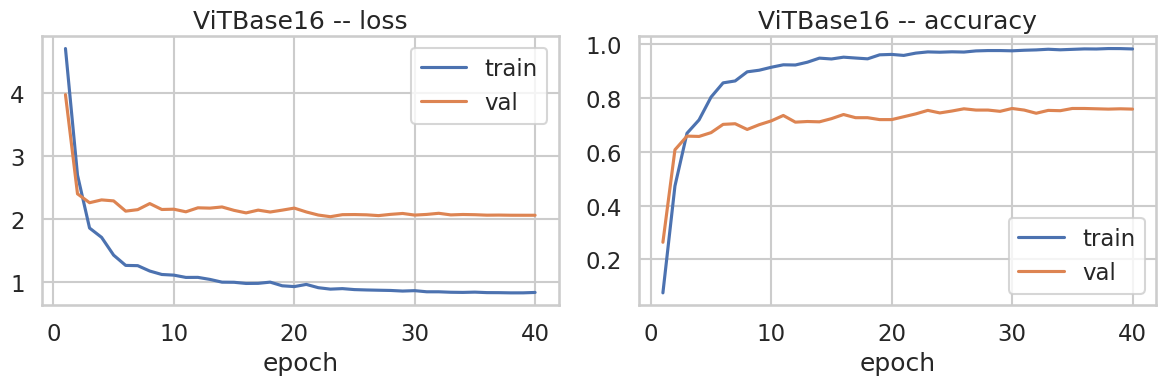

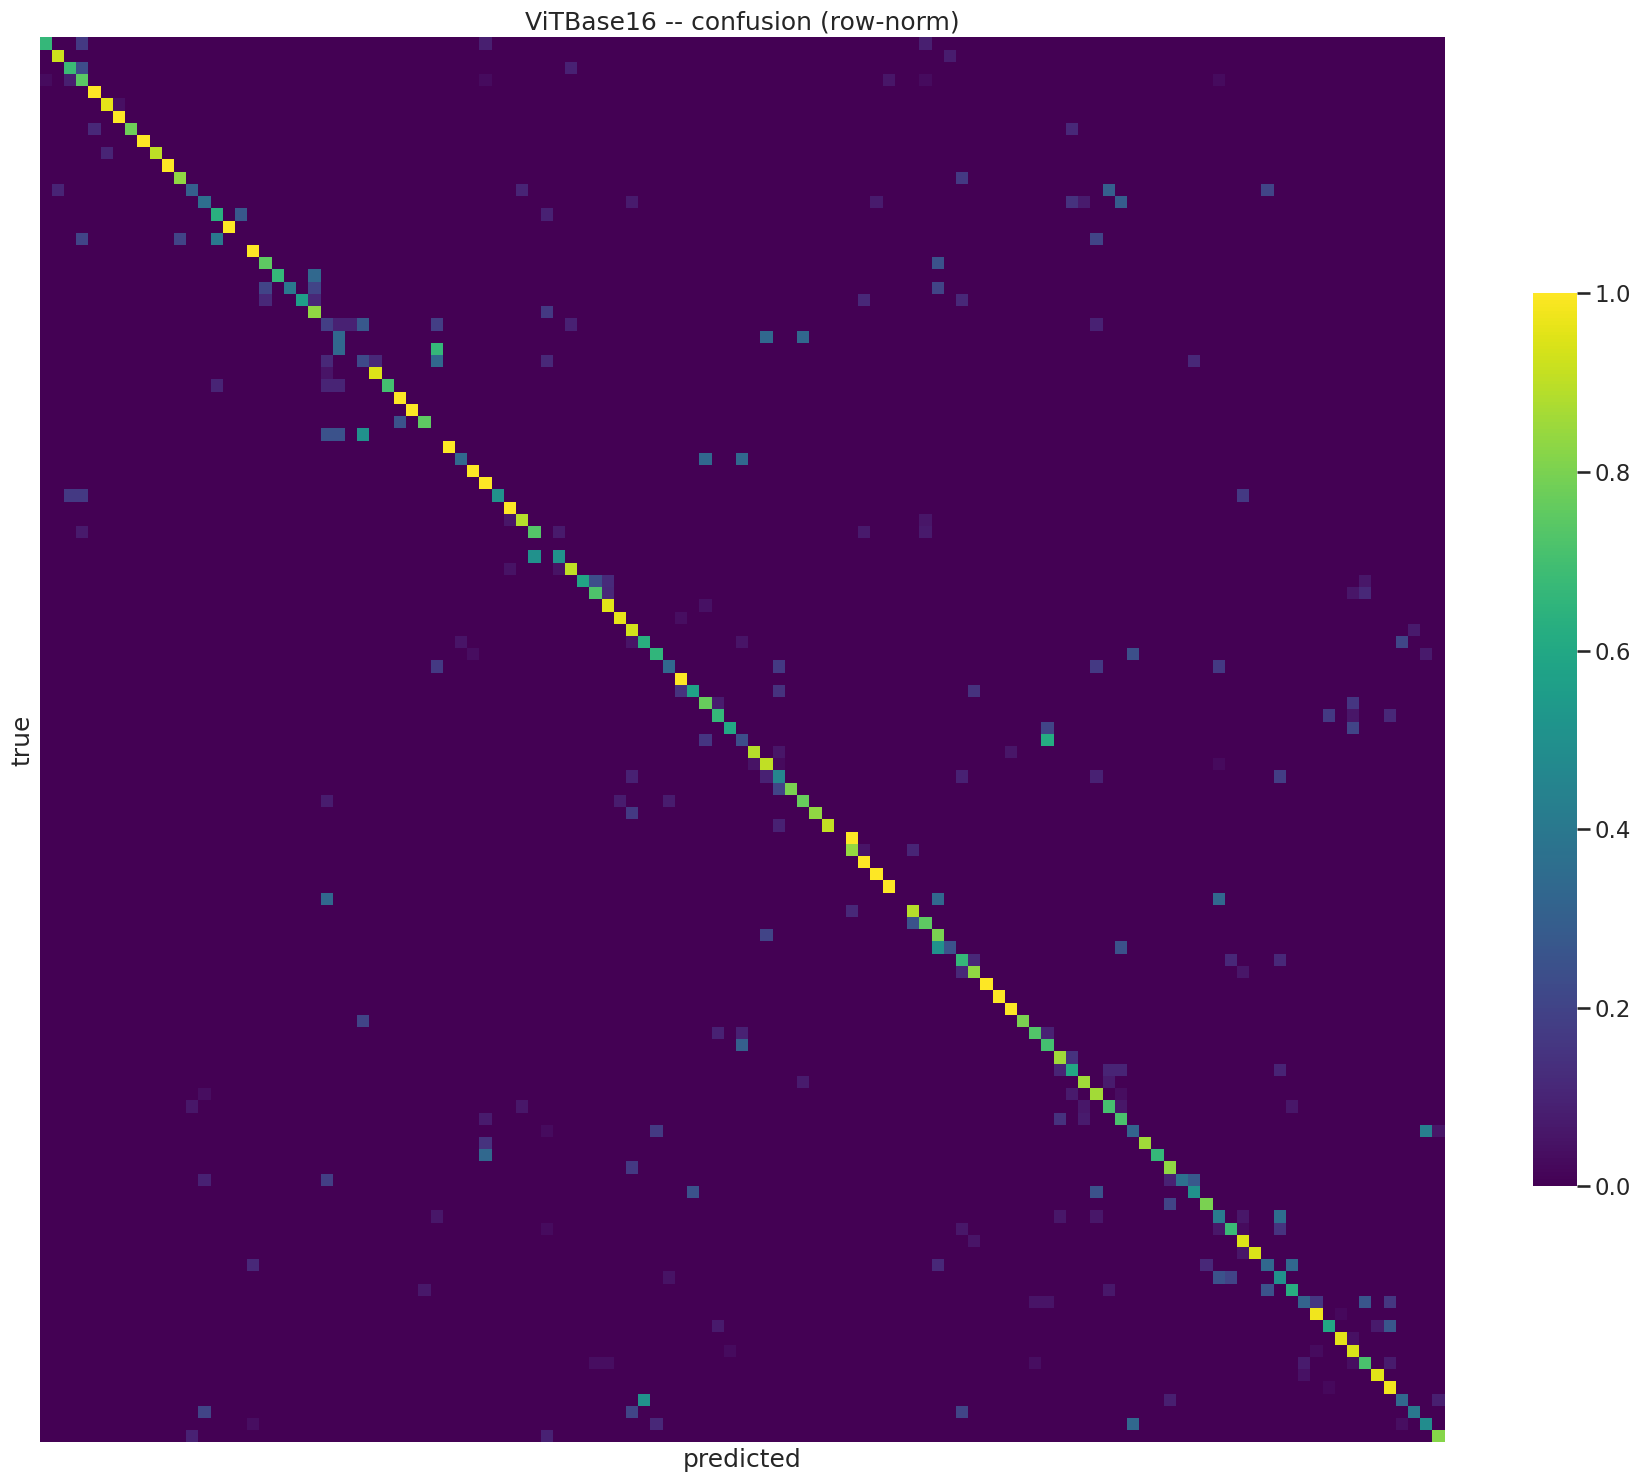

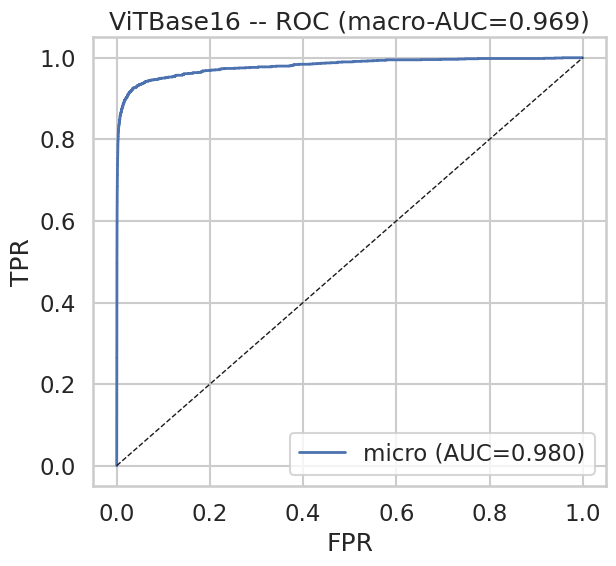

ViTBase16 is a transformer -- Grad-CAM skipped (use attention rollout in Stage 4).

  Training: SwinTiny  (seed=42)



model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[SwinTiny] ep1/40 lr=2.0e-05 trL=5.010 vL=5.090 trA=0.019 vA=0.041
[SwinTiny] ep2/40 lr=3.5e-05 trL=4.123 vL=3.221 trA=0.209 vA=0.453
[SwinTiny] ep3/40 lr=5.0e-05 trL=2.703 vL=2.664 trA=0.475 vA=0.540
[SwinTiny] ep4/40 lr=5.0e-05 trL=2.192 vL=2.425 trA=0.587 vA=0.606
[SwinTiny] ep5/40 lr=5.0e-05 trL=1.812 vL=2.293 trA=0.692 vA=0.645
[SwinTiny] ep6/40 lr=4.9e-05 trL=1.591 vL=2.293 trA=0.754 vA=0.652
[SwinTiny] ep7/40 lr=4.9e-05 trL=1.464 vL=2.182 trA=0.800 vA=0.683
[SwinTiny] ep8/40 lr=4.8e-05 trL=1.388 vL=2.160 trA=0.831 vA=0.701
[SwinTiny] ep9/40 lr=4.7e-05 trL=1.299 vL=2.147 trA=0.852 vA=0.689
[SwinTiny] ep10/40 lr=4.6e-05 trL=1.254 vL=2.179 trA=0.862 vA=0.674
[SwinTiny] ep11/40 lr=4.4e-05 trL=1.208 vL=2.112 trA=0.881 vA=0.710
[SwinTiny] ep12/40 lr=4.3e-05 trL=1.190 vL=2.179 trA=0.888 vA=0.702
[SwinTiny] ep13/40 lr=4.2e-05 trL=1.162 vL=2.185 trA=0.901 vA=0.688
[SwinTiny] ep14/40 lr=4.0e-05 trL=1.129 vL=2.159 trA=0.912 vA=0.690
[SwinTiny] ep15/40 lr=3.8e-05 trL=1.094 vL=2.122 trA=0.92

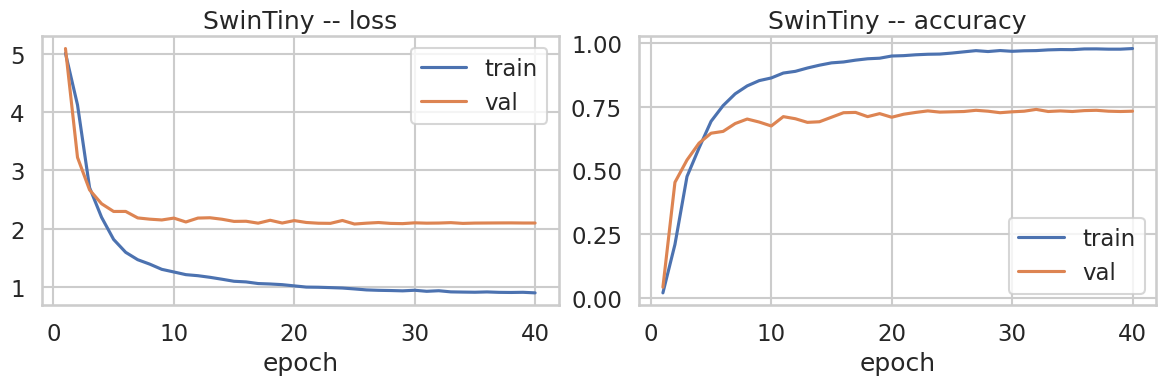

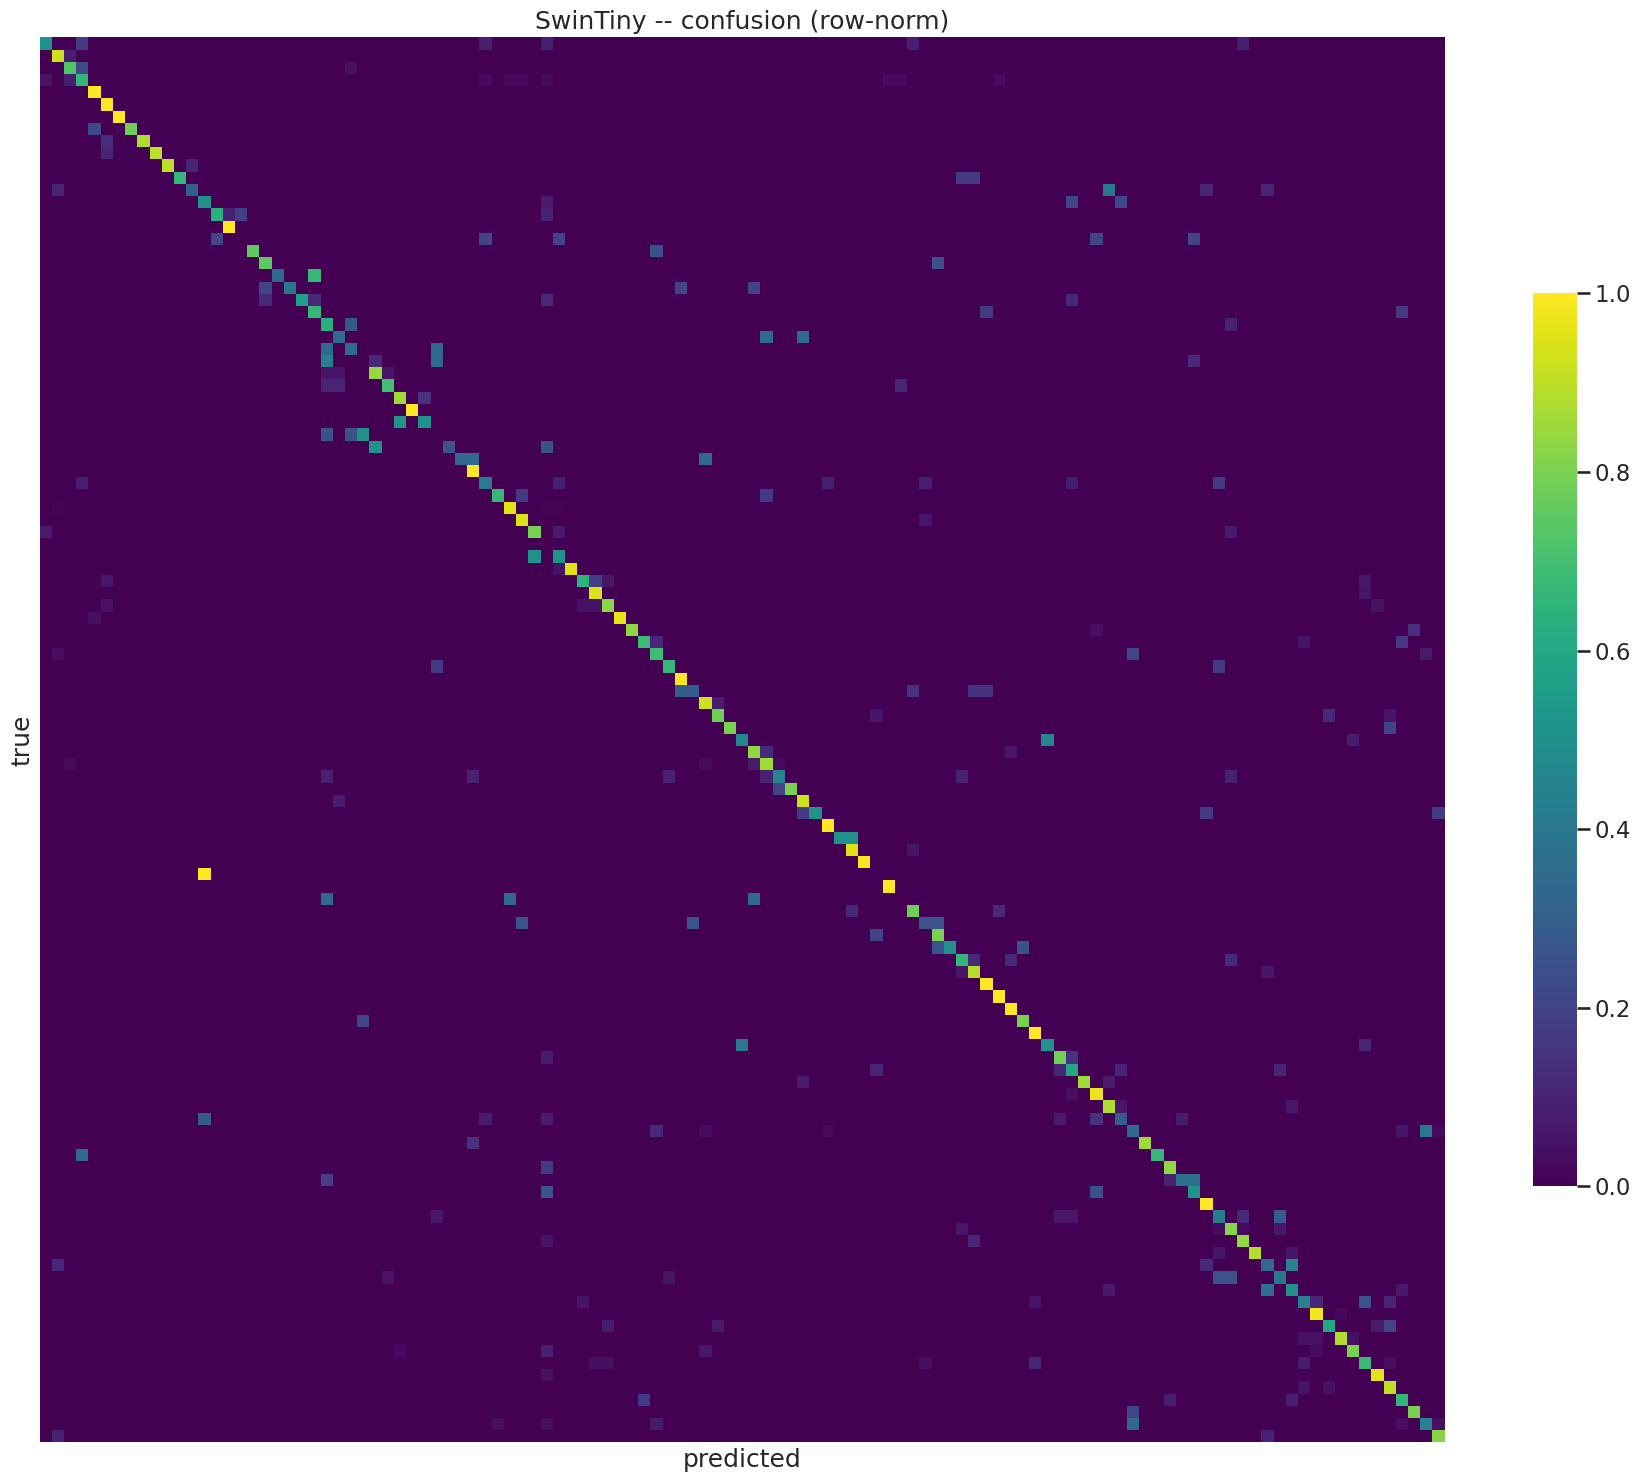

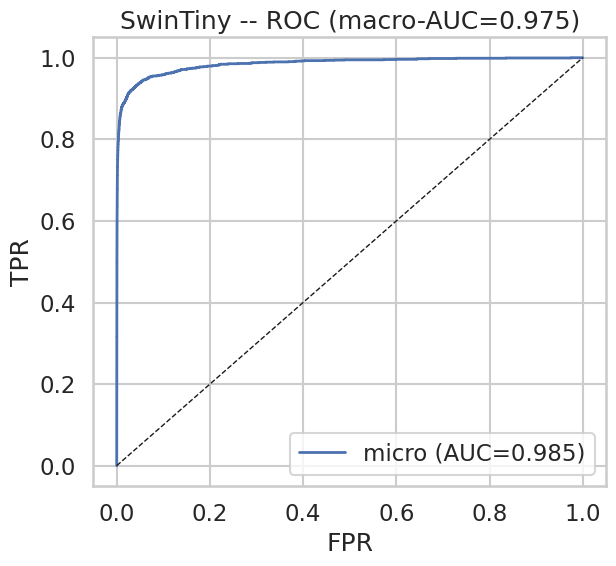

SwinTiny is a transformer -- Grad-CAM skipped (use attention rollout in Stage 4).

Both models retrained and saved.


In [9]:
# ============ MAIN LOOP -- RETRAIN VIT-B/16 + SWIN-TINY, SEED 42 ============
trained_models = {}  # kept in memory for the built-in sanity check below

for MODEL_NAME in MODELS_TO_TRAIN:
    print(f"\n{'='*60}")
    print(f"  Training: {MODEL_NAME}  (seed=42)")
    print(f"{'='*60}\n")

    t0 = time.time()
    model, img_size, hist, Y, P, PR = train_one(MODEL_NAME)
    train_time = time.time()-t0
    trained_models[MODEL_NAME] = (model, img_size)

    metrics, cm = compute_metrics(Y, P, PR, NUM_CLASSES)
    dep = deployment(model, img_size)

    result = {
        "model_name": MODEL_NAME, "seed": 42, "history": hist,
        "y_true": Y, "y_pred": P, "y_prob": PR,
        "metrics": metrics, "cm": cm, "deployment": dep,
        "img_size": img_size, "train_time_sec": train_time,
        "class_names": CLASS_NAMES,
    }
    pickle.dump(result, open(OUTDIR/f"result_{MODEL_NAME}.pkl","wb"))
    print("SAVED", OUTDIR/f"result_{MODEL_NAME}.pkl", f"  ({train_time/60:.1f} min)")
    print({k: round(v,4) for k,v in metrics.items() if isinstance(v, float)})
    print("deployment:", {k: round(v,2) for k,v in dep.items()})

    plot_model_figures(MODEL_NAME, hist, Y, P, PR, img_size)
    plot_gradcam(MODEL_NAME, model, img_size)

print("\nBoth models retrained and saved.")

## Section 10 -- Built-in sanity check (reruns Notebook D2's collapse-vs-scatter diagnostic
on the freshly-trained models, right now, with no need to download anything first)

In [10]:
# ============ BUILT-IN SANITY CHECK (same methodology as Notebook D2) ============
idx2label = {i: c for c, i in label2idx.items()}
_train_class_counts = train_df["label"].value_counts()
MAJORITY_CLASS = _train_class_counts.index[0]

def sample_df(df, n, seed=42):
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(df), size=min(n, len(df)), replace=False)
    return df.iloc[idx].reset_index(drop=True)

def quick_diagnostic(name, df, split_name, model, img_size):
    tf = transforms.Compose([transforms.Resize((img_size, img_size)), transforms.ToTensor(),
                              transforms.Normalize(MEAN, STD)])
    model.eval(); rows = []
    with torch.no_grad():
        for r in df.itertuples():
            x = tf(Image.open(r.filepath).convert("RGB")).unsqueeze(0).to(device)
            probs = F.softmax(model(x), dim=1)[0]
            top5 = torch.topk(probs, k=5).indices.tolist(); pred = top5[0]
            true_idx = label2idx[r.label]
            rows.append({"pred_label": idx2label[pred], "correct": int(pred==true_idx),
                         "top5_correct": int(true_idx in top5), "max_prob": float(probs[pred])})
    out = pd.DataFrame(rows)
    acc, top5acc, conf = out["correct"].mean(), out["top5_correct"].mean(), out["max_prob"].mean()
    pred_counts = out["pred_label"].value_counts()
    top_pred, top_pred_frac = pred_counts.index[0], pred_counts.iloc[0]/len(out)
    print(f"  [{name} / {split_name}]  top1_acc={acc:.4f}  top5_acc={top5acc:.4f}  mean_conf={conf:.4f}  "
          f"unique_preds={pred_counts.shape[0]}/{NUM_CLASSES}  "
          f"top_pred={top_pred!r} ({top_pred_frac:.4f}){'  <-- COLLAPSE' if top_pred_frac>0.3 else ''}")
    return acc

print("="*70)
print("SANITY CHECK -- same quick-subset methodology that caught the original failure:")
for name, (model, img_size) in trained_models.items():
    train_sample = sample_df(train_df, 120, seed=42)
    val_sample   = sample_df(val_df, 120, seed=42)
    tr_acc = quick_diagnostic(name, train_sample, "train", model, img_size)
    va_acc = quick_diagnostic(name, val_sample,   "val",   model, img_size)
    verdict = "LOOKS FIXED" if (tr_acc >= 0.40 and va_acc >= 0.40) else "STILL BROKEN -- do not use these numbers"
    print(f"  >>> {name}: {verdict}\n")
print("="*70)

SANITY CHECK -- same quick-subset methodology that caught the original failure:
  [ViTBase16 / train]  top1_acc=0.9667  top5_acc=1.0000  mean_conf=0.8366  unique_preds=61/115  top_pred='wheat stripe rust' (0.0583)
  [ViTBase16 / val]  top1_acc=0.7167  top5_acc=0.9250  mean_conf=0.6090  unique_preds=61/115  top_pred='apple scab' (0.0500)
  >>> ViTBase16: LOOKS FIXED

  [SwinTiny / train]  top1_acc=0.9667  top5_acc=1.0000  mean_conf=0.8422  unique_preds=61/115  top_pred='wheat stripe rust' (0.0583)
  [SwinTiny / val]  top1_acc=0.7083  top5_acc=0.9083  mean_conf=0.6260  unique_preds=61/115  top_pred='tomato early blight' (0.0667)
  >>> SwinTiny: LOOKS FIXED



## Wrap-up -- zip checkpoints, result pkls, and figures for download

In [11]:
import zipfile as _zf
zip_path = Path("/kaggle/working/plantseg_r2_notebookE_seed42_retrain.zip")
with _zf.ZipFile(zip_path, "w", _zf.ZIP_DEFLATED) as zf:
    for p in sorted(OUTDIR.rglob("*")):
        if p.is_file():
            zf.write(p, p.relative_to(OUTDIR))
print(f"Archive: {zip_path.name}  ({zip_path.stat().st_size/1024/1024:.2f} MB)")
print("Files included:")
for p in sorted(OUTDIR.rglob("*")):
    if p.is_file():
        print(" ", p.relative_to(OUTDIR))
print("\nDownload from the Kaggle Output tab. ViTBase16_best.pt / SwinTiny_best.pt are drop-in")
print("replacements for the broken seed-42 checkpoints -- same filenames, same convention.")

Archive: plantseg_r2_notebookE_seed42_retrain.zip  (403.91 MB)
Files included:
  SwinTiny_best.pt
  ViTBase16_best.pt
  figures/SwinTiny_confusion.png
  figures/SwinTiny_loss_acc.png
  figures/SwinTiny_roc.png
  figures/ViTBase16_confusion.png
  figures/ViTBase16_loss_acc.png
  figures/ViTBase16_roc.png
  result_SwinTiny.pkl
  result_ViTBase16.pkl

Download from the Kaggle Output tab. ViTBase16_best.pt / SwinTiny_best.pt are drop-in
replacements for the broken seed-42 checkpoints -- same filenames, same convention.
